In [15]:
import os, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import albumentations as A
from sklearn.model_selection import train_test_split
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

DATA_DIR = '/kaggle/input/competitions/cassava-leaf-disease-classification'
OUT_DIR  = '/kaggle/working/processed'     
IMG_SIZE = 256
SEED = 42
os.makedirs(OUT_DIR, exist_ok=True)

def show(imgs, titles=None, cols=6, size=3):
    rows = int(np.ceil(len(imgs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis('off')
    for i, im in enumerate(imgs):
        axes[i].imshow(im)
        if titles is not None: axes[i].set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

12838 4279 4280


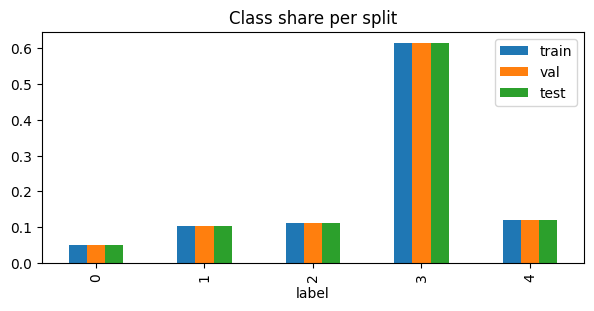

In [16]:
def split_data(data_dir=DATA_DIR, seed=SEED):
    df = pd.read_csv(f'{data_dir}/train.csv')
    df['path'] = data_dir + '/train_images/' + df['image_id']
    train_df, rest = train_test_split(df, test_size=0.4, stratify=df['label'], random_state=seed)
    val_df, test_df = train_test_split(rest, test_size=0.5, stratify=rest['label'], random_state=seed)
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

train_df, val_df, test_df = split_data()
print(len(train_df), len(val_df), len(test_df))

dist = pd.DataFrame({n: d['label'].value_counts(normalize=True).sort_index()
                     for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]})
dist.plot(kind='bar', figsize=(7, 3), title='Class share per split'); plt.show()

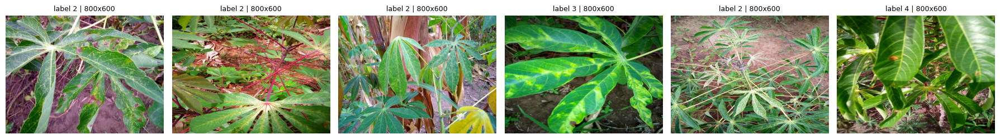

In [17]:
def load_image(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

samples = train_df.sample(6)
raw = [load_image(p) for p in samples.path]
show(raw, [f'label {l} | {im.shape[1]}x{im.shape[0]}' for l, im in zip(samples.label, raw)])

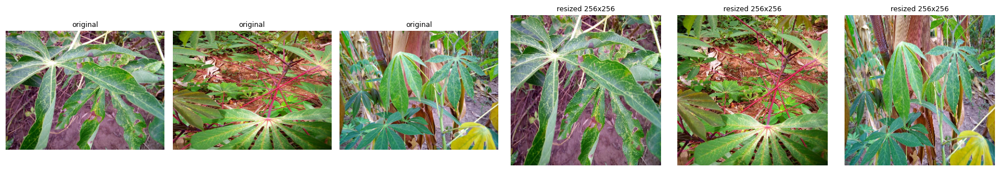

In [18]:
def resize_image(img, size=IMG_SIZE):
    return cv2.resize(img, (size, size))

resized = [resize_image(im) for im in raw]
show(raw[:3] + resized[:3], ['original'] * 3 + ['resized 256x256'] * 3)

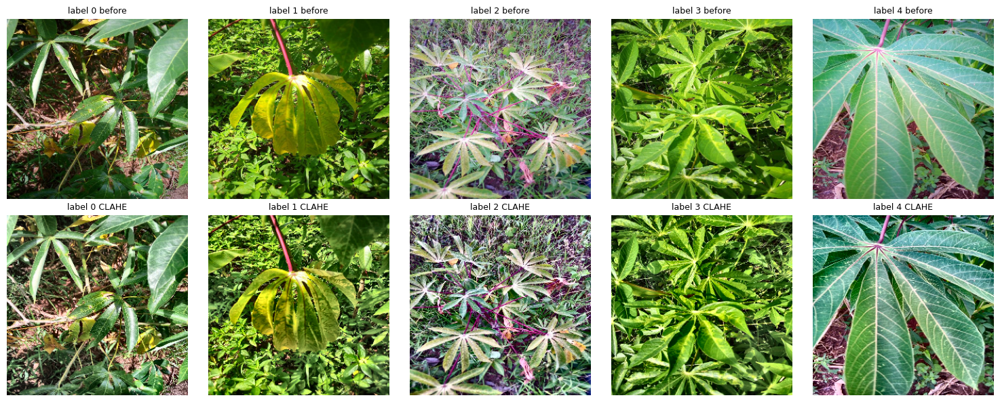

In [19]:
def clahe_lab(img_rgb, clip_limit=3.0, grid=(7, 7)):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)

per_class = [resize_image(load_image(train_df[train_df.label == c].sample(1).path.iloc[0])) for c in range(5)]
show(per_class + [clahe_lab(im) for im in per_class],
     [f'label {c} before' for c in range(5)] + [f'label {c} CLAHE' for c in range(5)], cols=5)

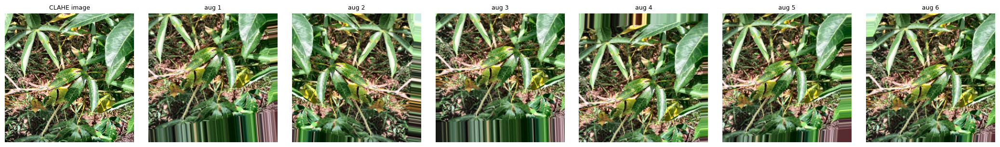

In [20]:
aug = A.Compose([
    A.Affine(rotate=(-20, 20),
             translate_percent={'x': (-0.2, 0.2), 'y': (-0.2, 0.2)},
             shear={'x': (0, 11.3), 'y': (0, 0)},
             border_mode=cv2.BORDER_REPLICATE, p=1.0),
    A.HorizontalFlip(p=0.5),
])

def augment_image(img):
    return aug(image=img)['image']

base = clahe_lab(per_class[0])
show([base] + [augment_image(base) for _ in range(6)], ['CLAHE image'] + [f'aug {i}' for i in range(1, 7)], cols=7)

In [21]:
def rescale(img):
    return img.astype(np.float32) / 255.0

x = rescale(augment_image(base))
print(x.shape, x.dtype, x.min(), x.max())

(256, 256, 3) float32 0.0 1.0


In [22]:
def process_and_save(row):
    out = f"{OUT_DIR}/{row['image_id'].rsplit('.', 1)[0]}.png"
    if not os.path.exists(out):
        img = clahe_lab(resize_image(load_image(row['path'])))
        cv2.imwrite(out, cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 1])
    return out

all_df = pd.concat([train_df.assign(split='train'), val_df.assign(split='val'), test_df.assign(split='test')],
                   ignore_index=True)
rows = all_df.to_dict('records')
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    all_df['proc_path'] = list(tqdm(ex.map(process_and_save, rows), total=len(rows)))

print(len(os.listdir(OUT_DIR)), 'images processed')

  0%|          | 0/21397 [00:00<?, ?it/s]

21397 images processed


In [23]:
for _, r in all_df.sample(5).iterrows():
    live  = clahe_lab(resize_image(load_image(r.path)))
    saved = load_image(r.proc_path)
    assert np.array_equal(live, saved), r.image_id
print('saved images match the live pipeline')

sample_paths = all_df.proc_path.sample(300, random_state=0)
assert all(load_image(p).shape == (IMG_SIZE, IMG_SIZE, 3) for p in sample_paths)
print('shapes OK')

saved images match the live pipeline
shapes OK


In [24]:
for name in ['train', 'val', 'test']:
    all_df[all_df.split == name].drop(columns='split').reset_index(drop=True)\
          .to_csv(f'/kaggle/working/{name}_split.csv', index=False)
print(os.listdir('/kaggle/working'))

['test_split.csv', 'train_split.csv', '.virtual_documents', 'val_split.csv', 'processed']


train


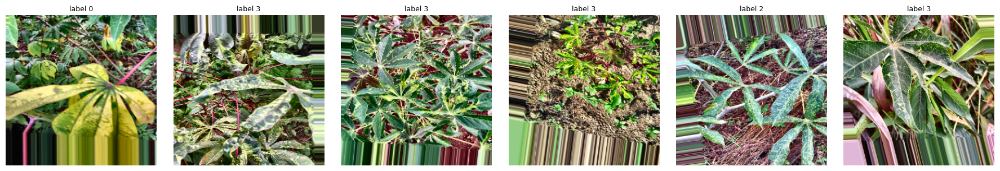

val


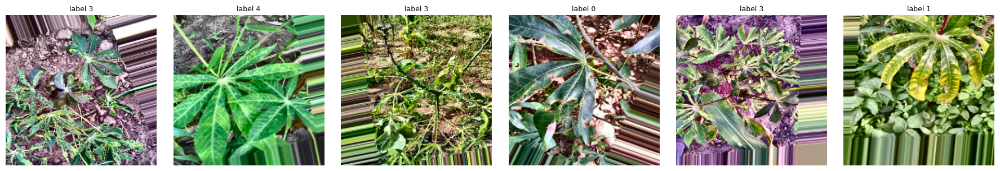

test


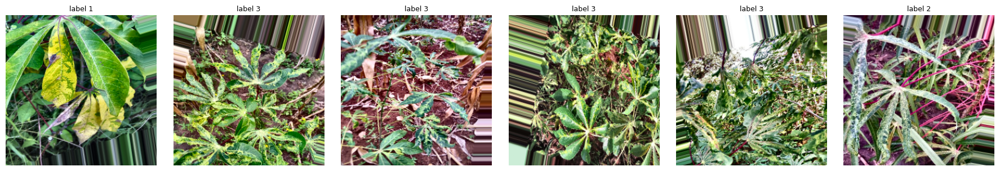

In [25]:
def load_processed(proc_path, use_aug=True):
    img = load_image(proc_path)           
    if use_aug: img = augment_image(img)  
    return rescale(img)

splits = {n: pd.read_csv(f'/kaggle/working/{n}_split.csv') for n in ['train', 'val', 'test']}
for name, d in splits.items():
    s = d.sample(6)
    print(name)
    show([load_processed(p) for p in s.proc_path], [f'label {l}' for l in s.label])

In [26]:
train_df = splits['train']
val_df   = splits['val']
test_df  = splits['test']